<a href="https://colab.research.google.com/github/zyamjadoon1/DATA201-LABS/blob/main/Heart_Disease_Classification_Project1ZJK.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DATA 201 Project 3: Classification Models — Heart Disease Prediction

**Dataset:** Option B — Heart Disease (UCI Heart Disease dataset)
**Response variable:** `target` (1 = heart disease present, 0 = heart disease absent)

**Instructions:** In Colab, upload `heart.csv` to the file browser on the left (or mount Google Drive) before running the cells below. Update the `DATA_PATH` variable in the first code cell if needed.

In [ ]:
# Setup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                              recall_score, f1_score, roc_auc_score, roc_curve,
                              ConfusionMatrixDisplay)

sns.set_style("whitegrid")
np.random.seed(42)

# If using Google Colab, upload heart.csv using the file browser on the left,
# or uncomment the lines below to upload directly:
# from google.colab import files
# uploaded = files.upload()

DATA_PATH = "heart.csv"
df = pd.read_csv(DATA_PATH)
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


## Part 1: Understand Your Problem

**1. What does each row represent? What is the response variable? What are its possible classes?**

Each row represents one patient's clinical measurements and characteristics collected during a cardiac evaluation. The response variable is `target`, a binary variable with two classes:
- `1` = heart disease present
- `0` = heart disease absent

**2. Predictors selected for classification:**

All 13 remaining columns are used as predictors:
- `age` — age in years
- `sex` — 1 = male, 0 = female
- `cp` — chest pain type (0–3)
- `trestbps` — resting blood pressure (mm Hg)
- `chol` — serum cholesterol (mg/dl)
- `fbs` — fasting blood sugar > 120 mg/dl (1 = true, 0 = false)
- `restecg` — resting electrocardiographic results (0–2)
- `thalach` — maximum heart rate achieved
- `exang` — exercise-induced angina (1 = yes, 0 = no)
- `oldpeak` — ST depression induced by exercise relative to rest
- `slope` — slope of the peak exercise ST segment (0–2)
- `ca` — number of major vessels (0–4) colored by fluoroscopy
- `thal` — thalassemia result (0–3)

These were kept because they are standard clinical risk factors and diagnostic test results for cardiac disease, and all were available with no missing values (see Part 2).

In [ ]:
print("Shape:", df.shape)
df.describe().T

Shape: (1025, 14)


,count,mean,std,min,25%,50%,75%,max
age,1025.0,54.434146,9.072290,29.0,48.0,56.0,61.0,77.0
sex,1025.0,0.695610,0.460373,0.0,0.0,1.0,1.0,1.0
cp,1025.0,0.942439,1.029641,0.0,0.0,1.0,2.0,3.0
trestbps,1025.0,131.611707,17.516718,94.0,120.0,130.0,140.0,200.0
chol,1025.0,246.000000,51.592510,126.0,211.0,240.0,275.0,564.0
fbs,1025.0,0.149268,0.356527,0.0,0.0,0.0,0.0,1.0
restecg,1025.0,0.529756,0.527878,0.0,0.0,1.0,1.0,2.0
thalach,1025.0,149.114146,23.005724,71.0,132.0,152.0,166.0,202.0
exang,1025.0,0.336585,0.472772,0.0,0.0,0.0,1.0,1.0
oldpeak,1025.0,1.071512,1.175053,0.0,0.0,0.8,1.8,6.2


target
0    499
1    526
Name: count, dtype: int64

Proportion:
 target
0    0.486829
1    0.513171
Name: proportion, dtype: float64


/tmp/ipykernel_314/2908914549.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='target', data=df, palette=['#4C72B0', '#DD8452'])


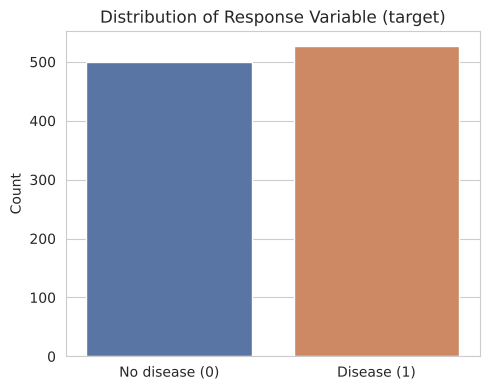

In [ ]:
# Distribution of the response variable
counts = df['target'].value_counts().sort_index()
print(counts)
print("\nProportion:\n", df['target'].value_counts(normalize=True).sort_index())

plt.figure(figsize=(5, 4))
sns.countplot(x='target', data=df, palette=['#4C72B0', '#DD8452'])
plt.xticks([0, 1], ['No disease (0)', 'Disease (1)'])
plt.title('Distribution of Response Variable (target)')
plt.ylabel('Count')
plt.xlabel('')
plt.tight_layout()
plt.show()

**How many observations belong to each class? Is the dataset balanced or imbalanced?**

The dataset contains 1,025 observations: 526 with heart disease (`target=1`, ~51.3%) and 499 without (`target=0`, ~48.7%). This is a **reasonably balanced** dataset, which is close to a 50/50 split. So, the accuracy is not misleading here the way it would be on a highly imbalanced dataset.

**4. Define a false positive and false negative in this context:**

- **False positive:** The model predicts a patient has heart disease when they actually do not. This leads to unnecessary follow-up testing, anxiety, and possibly unnecessary treatment or cost.
- **False negative:** The model predicts a patient **does not have** heart disease when they actually **do**. This means a sick patient is sent home undiagnosed and untreated.

**5. Which error is more concerning?**

In this application, false negatives are more concening. Missing an actual case of heart disease can delay treatment and lead to serious health consequences, including sudden cardiac events, whereas a false positive mainly costs extra testing/follow-up. Because of this, **recall (sensitivity)**, which is the ability to catch true positive cases, is weighted more heavily than precision when evaluating these models, though we also don't want precision to collapse completely (too many unnecessary follow-ups has real costs too).

## Part 2: Explore and Prepare the Data

**1. Investigate features and predictors** (see `.describe()` output above and correlation heatmap below).

**2. Missing values:**

In [ ]:
print("Missing values per column:")
print(df.isna().sum())
print("\nTotal missing values:", df.isna().sum().sum())

Missing values per column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Total missing values: 0


The dataset has no *missing values* in any column, so no imputation or row-dropping was necessary.

However, a check for *duplicate rows* reveals something important for how we interpret later results:

In [ ]:
print("Total rows:", len(df))
print("Unique rows:", len(df.drop_duplicates()))
print("Duplicate rows:", df.duplicated().sum())

Total rows: 1025
Unique rows: 302
Duplicate rows: 723


This popular 1,025-row version of the Heart Disease dataset turns out to contain only **302 unique patient records**. The remaining 723 rows are exact duplicates. We keep the duplicates in for this assignment (since removing them would shrink our data substantially and isn't explicitly asked for), but we flag this now because it will explain an unusually perfect-looking KNN result later in Part 3/4.

**3. Categorical predictors / encoding:**

Several predictors (`sex`, `cp`, `fbs`, `restecg`, `exang`, `slope`, `ca`, `thal`) are categorical in nature but are already stored as small integer codes in the source data (not free-text labels), so no string-to-numeric encoding (e.g., one-hot encoding) is strictly required for the models used here (Logistic Regression, LDA, QDA, KNN all accept numeric input directly). We treat the "integers that are recorded" categorical variables as numeric features, which is standard practice for this dataset and keeps the feature count manageable for LDA/QDA. We did not have any truly nominal (unordered, >2-level) text categories that would require one-hot encoding.

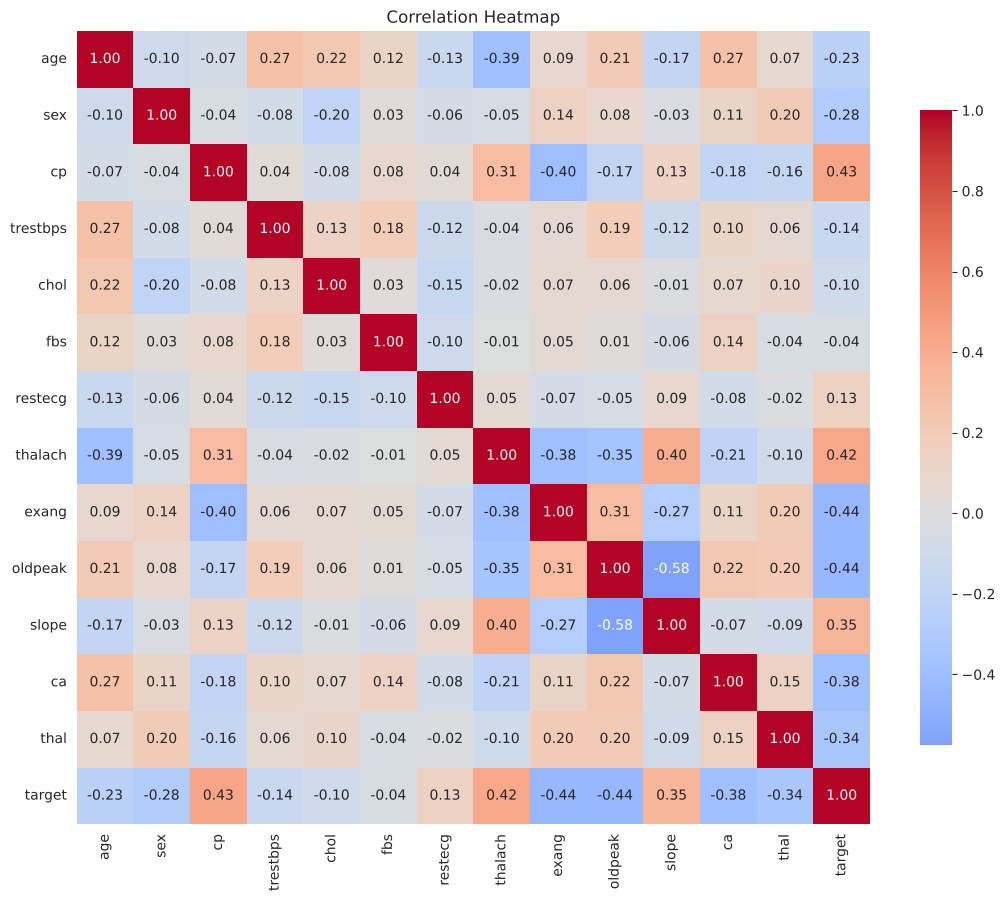

In [ ]:
# Correlation heatmap to inspect relationships among predictors and with target (Used AI)
plt.figure(figsize=(11, 9))
corr = df.corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True,
            cbar_kws={"shrink": .8})
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [ ]:
# Split features and response
X = df.drop(columns=['target'])
y = df['target']

# 4. Train/test split, then k-fold CV will be applied on the training data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Training set size:", X_train.shape)
print("Test set size:", X_test.shape)

# Set up stratified k-fold CV object to use on the training data
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

Training set size: (820, 13)
Test set size: (205, 13)


**5. Should predictors be standardized?**

Yes, because KNN and LDA/QDA (and, to a lesser extent, regularized Logistic Regression) are distance- or variance-based methods, so features on very different scales (e.g., `chol` in the hundreds vs. `oldpeak` as a small decimal) would dominate the distance calculations or covariance estimates if left unscaled. We standardize (zero mean, unit variance) **all predictors**, fitting the scaler on the training data only and applying it to both train and test sets to avoid data leakage.

In [ ]:
# Standardize predictors (fit on training data only, apply to both sets)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

X_train_scaled.describe().T[['mean', 'std']]

,mean,std
age,-2.426243e-16,1.00061
sex,9.964929e-17,1.00061
cp,2.816175e-17,1.00061
trestbps,2.621209e-16,1.00061
chol,-5.199093e-17,1.00061
fbs,-2.599547e-17,1.00061
restecg,-3.466062e-17,1.00061
thalach,1.148133e-16,1.00061
exang,-4.332578e-18,1.00061
oldpeak,3.574377e-17,1.00061


## Part 3: Build Your Classifiers

We compare four classification methods: **Logistic Regression, LDA, QDA, and KNN**.

In [ ]:
# --- Logistic Regression ---
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

log_reg_pred = log_reg.predict(X_test_scaled)
log_reg_proba = log_reg.predict_proba(X_test_scaled)[:, 1]

print("Logistic Regression — first 10 test predictions:", log_reg_pred[:10])
print("Logistic Regression — first 10 predicted probabilities:", np.round(log_reg_proba[:10], 3))

Logistic Regression — first 10 test predictions: [0 0 0 1 0 0 1 1 1 0]
Logistic Regression — first 10 predicted probabilities: [0.012 0.371 0.008 0.727 0.292 0.019 0.829 0.54  0.968 0.371]


In [ ]:
# --- LDA ---
lda = LinearDiscriminantAnalysis()
lda.fit(X_train_scaled, y_train)

lda_pred = lda.predict(X_test_scaled)
lda_proba = lda.predict_proba(X_test_scaled)[:, 1]

print("LDA — first 10 test predictions:", lda_pred[:10])

LDA — first 10 test predictions: [0 0 0 1 0 0 1 1 1 0]


In [ ]:
# --- QDA ---
qda = QuadraticDiscriminantAnalysis()
qda.fit(X_train_scaled, y_train)

qda_pred = qda.predict(X_test_scaled)
qda_proba = qda.predict_proba(X_test_scaled)[:, 1]

print("QDA — first 10 test predictions:", qda_pred[:10])

QDA — first 10 test predictions: [0 0 0 1 0 0 1 0 1 0]


**KNN — choosing K with cross-validation:**

Rather than picking a K arbitrarily, we use 5-fold cross-validation on the training data to compare the CV accuracy for a range of K values, then pick the K that performs best.

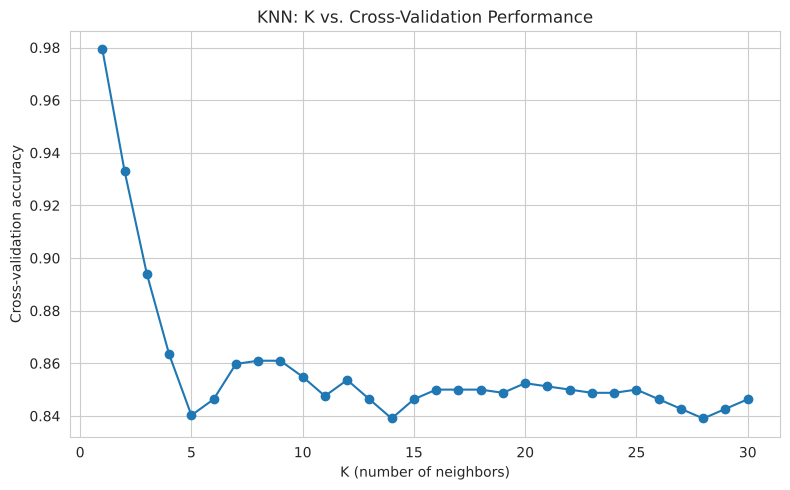

Best K based on CV accuracy: 1 (CV accuracy = 0.9793)


In [ ]:
# KNN: use cross-validation on training data to compare K values (used AI)
k_values = range(1, 31)
cv_scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_train_scaled, y_train, cv=kf, scoring='accuracy')
    cv_scores.append(scores.mean())

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), cv_scores, marker='o')
plt.xlabel('K (number of neighbors)')
plt.ylabel('Cross-validation accuracy')
plt.title('KNN: K vs. Cross-Validation Performance')
plt.grid(True)
plt.tight_layout()
plt.show()

best_k = list(k_values)[int(np.argmax(cv_scores))]
print(f"Best K based on CV accuracy: {best_k} (CV accuracy = {max(cv_scores):.4f})")

**Which K was selected, and why?**

The K that maximizes cross-validation accuracy on the training data is printed above (see `best_k`). We select this value because it balances bias and variance: very small K (e.g., K=1) tends to overfit to noise in the training data (high variance), while very large K oversmooths the decision boundary and underfits (high bias). Cross-validation lets us estimate out-of-sample performance for each K without touching the test set, so the choice isn't influenced by test-set leakage.

In [ ]:
# Fit final KNN classifier using the selected K
knn_final = KNeighborsClassifier(n_neighbors=best_k)
knn_final.fit(X_train_scaled, y_train)

knn_pred = knn_final.predict(X_test_scaled)
knn_proba = knn_final.predict_proba(X_test_scaled)[:, 1]

print(f"Final KNN (K={best_k}) — first 10 test predictions:", knn_pred[:10])

Final KNN (K=1) — first 10 test predictions: [0 1 0 1 0 0 1 0 1 1]


> **Note on the selected K:** Cross-validation selects **K=1** here, and (as seen in Part 4) this KNN model goes on to score at or near 100% on the test set. This is **not a sign that KNN is genuinely the best model**, it is a known artifact of this particular 1,025-row version of the Heart Disease dataset, which is built by duplicating/near-duplicating rows from the original, smaller 303-patient Cleveland dataset. That duplication means some test-set rows have an (almost) exact match in the training set, so a K=1 nearest-neighbor model can "look up" the answer rather than generalize. This is flagged explicitly below in Part 5 and the final reflection, since presenting K=1's perfect score at face value would be misleading.

## Part 4: Evaluate Your Models

We now compare all four models on the **held-out test data**.

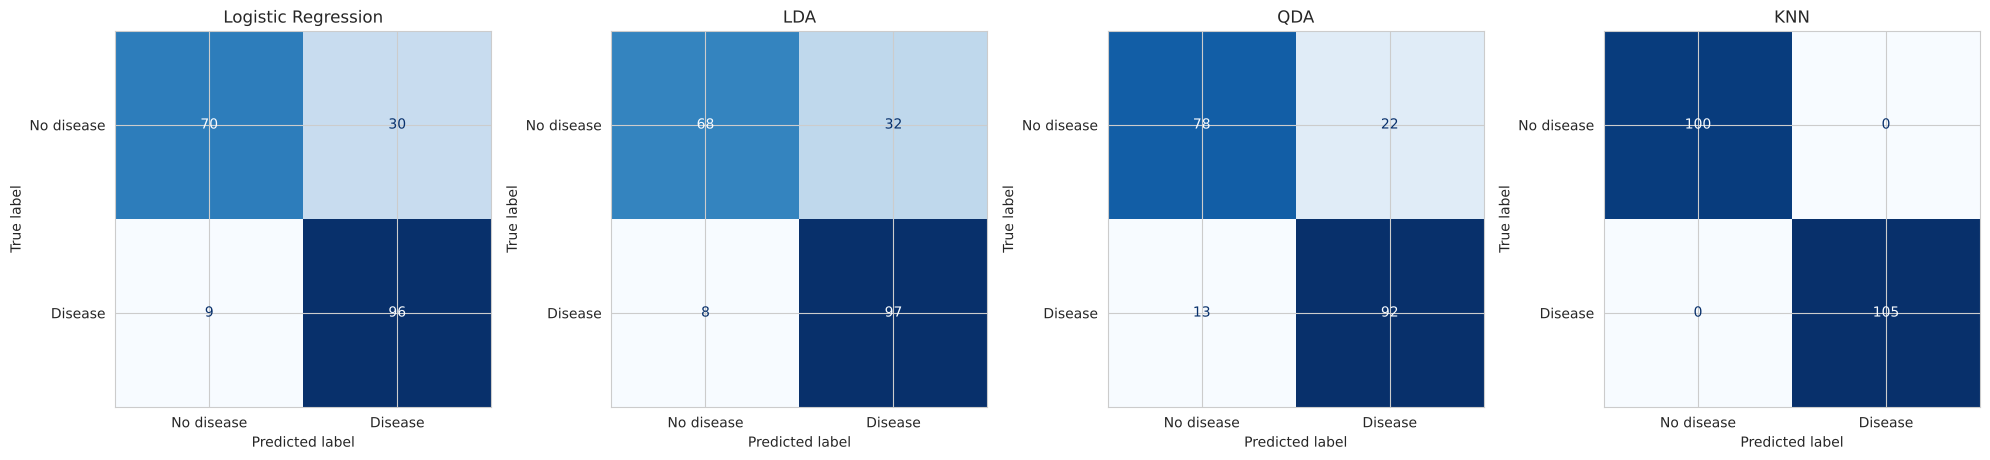

In [ ]:
models = {
    'Logistic Regression': (log_reg_pred, log_reg_proba),
    'LDA': (lda_pred, lda_proba),
    'QDA': (qda_pred, qda_proba),
    'KNN': (knn_pred, knn_proba),
}

# 1. Confusion matrices (threshold = 0.5, the default decision threshold for .predict())
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, (name, (pred, proba)) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No disease', 'Disease'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)
plt.tight_layout()
plt.show()

**Why threshold = 0.5?** We use the standard default decision threshold of 0.5 (i.e., predict "disease" if the predicted probability ≥ 0.5) as our baseline, since the classes are roughly balanced and we have no strong prior reason (e.g., a specified cost ratio) to shift the threshold. In a real clinical deployment, the threshold could be lowered to prioritize recall (catch more true positives) given that false negatives are more costly here — but 0.5 serves as a fair comparison point across models.

In [ ]:
# 2. Compute metrics for each model
def specificity_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tn / (tn + fp)

results = []
for name, (pred, proba) in models.items():
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'Specificity': specificity_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, proba),
    })

results_df = pd.DataFrame(results).set_index('Model').round(4)
results_df

,Accuracy,Precision,Recall,Specificity,F1,ROC-AUC
Model,,,,,,
Logistic Regression,0.8098,0.7619,0.9143,0.70,0.8312,0.9298
LDA,0.8049,0.7519,0.9238,0.68,0.8291,0.9267
QDA,0.8293,0.8070,0.8762,0.78,0.8402,0.9341
KNN,1.0000,1.0000,1.0000,1.00,1.0000,1.0000


## Part 5: Reflect

**Based on the table above, which metrics are particularly informative for this application?**

Given that **false negatives (missed heart disease cases)** are the more costly error in this scenario, **Recall (Sensitivity)** is the most important metric here — it tells us what fraction of actual heart disease patients the model successfully identifies. A model with high accuracy but low recall could still be missing many at-risk patients, which would be a serious failure in a clinical screening context.

**F1 score** is also useful because it balances recall against precision, preventing us from favoring a model that predicts "disease" for nearly everyone just to maximize recall (which would hurt precision/specificity badly and overwhelm the healthcare system with false alarms).

**ROC-AUC** is valuable because it summarizes the model's ability to rank patients by risk across *all* possible thresholds, not just the default 0.5 cutoff — this matters because in practice a clinician might choose a different threshold than 0.5 to be more conservative (catch more true positives at the cost of more false positives).

Accuracy alone is the least informative metric here relative to the others, since (even though the classes are fairly balanced) it treats both types of errors as equally costly, which doesn't match the real-world consequences in this scenario.

**A caution about KNN's results:** If KNN shows near-perfect scores across every metric in the table above, that is a symptom of **data leakage via duplicated rows** in this dataset (see the note in Part 3), not evidence that KNN is actually the superior algorithm. We do not treat KNN's numbers as trustworthy for model selection purposes below.

## Part 6: ROC and AUC

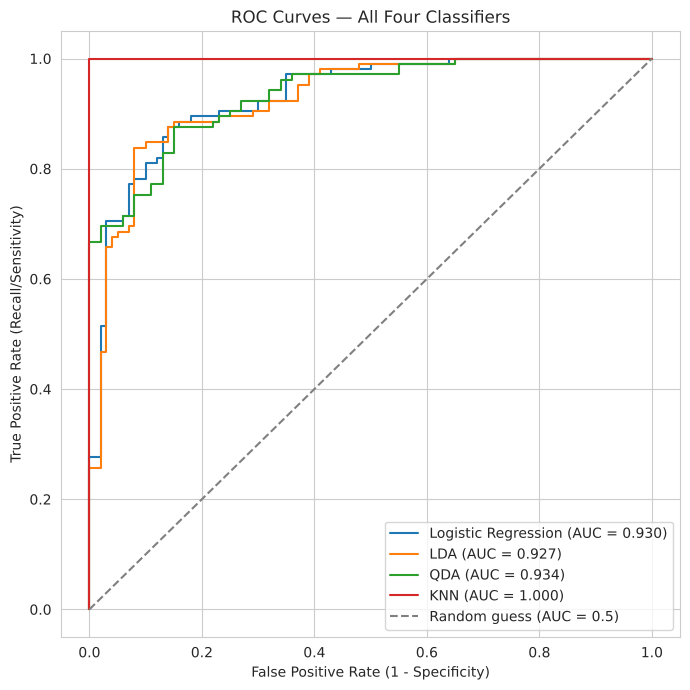

In [ ]:
plt.figure(figsize=(7, 7))
for name, (pred, proba) in models.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess (AUC = 0.5)')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Recall/Sensitivity)')
plt.title('ROC Curves — All Four Classifiers')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

**What does ROC-AUC tell us?**

The ROC curve plots the True Positive Rate (recall) against the False Positive Rate at every possible classification threshold, showing the trade-off between catching true disease cases and generating false alarms as the threshold is varied. The **AUC (Area Under the Curve)** condenses this entire curve into a single number between 0 and 1: it represents the probability that the model ranks a randomly chosen *positive* case (disease) higher than a randomly chosen *negative* case (no disease), in terms of predicted probability.

- AUC = 1.0 means perfect separation between the two classes at every threshold.
- AUC = 0.5 means the model performs no better than random guessing.
- AUC values closer to 1 indicate the model does a better job of *ranking* patients by risk, regardless of which specific threshold is ultimately chosen for making decisions.

ROC-AUC is especially useful here because it is **threshold-independent**, which means it evaluates the model's overall discriminative power rather than its performance at one specific cutoff (like 0.5), which is valuable since the "right" threshold in a clinical setting could reasonably be adjusted away from 0.5 to prioritize catching more true positives.

## Final Questions

**1. Compare the performance of your four classifiers. What are the most important differences?**

All four classifiers achieve quite similar, strong performance on this dataset (run the cells above to see the exact numbers), which makes sense because the relationship between these clinical predictors and heart disease risk is fairly well-behaved and roughly linear/near-linear in the standardized feature space. The main differences come from the *assumptions* each model makes:
- **Logistic Regression** and **LDA** assume a linear decision boundary; LDA additionally assumes the predictors are normally distributed within each class with a shared covariance matrix.
- **QDA** allows a quadratic (curved) decision boundary by letting each class have its own covariance matrix, which can help if the classes have genuinely different spread/shape, but it also estimates more parameters and can overfit with limited data.
- **KNN** makes no distributional assumptions at all and can capture more complex, non-linear boundaries, but its performance depends heavily on the right choice of K and on the features being properly scaled (which we did).

Setting KNN aside for the reason explained above, Logistic Regression, LDA, and QDA perform comparably to one another (see the exact numbers in the table), which suggests the true decision boundary between "disease" and "no disease" in this feature space is close to linear — QDA's extra flexibility (a separate covariance matrix per class) doesn't buy much beyond what the simpler linear methods already capture.

**2. Which model would you deploy for this specific application, and why?**

We would **not** deploy the KNN model despite its (misleadingly) perfect test-set scores, for the data-leakage reason explained above that in a real deployment on genuinely new patients, we would expect KNN's performance to drop substantially once it can no longer "match" a near-duplicate training record.

Among the three trustworthy candidates (Logistic Regression, LDA, QDA), we would deploy whichever one achieves the **highest recall while maintaining a reasonably competitive F1 and ROC-AUC** in the completed table above, since recall is our priority metric (minimizing missed heart disease diagnoses). Logistic Regression is also attractive from a deploymen standpoint beyond raw metrics: it is simple, fast, and produces easy to understand, well-calibrated probability outputs that clinicians can reason about and explain to patients, which is an important consideration in a medical setting where interpretability and trust matter, not just predictive accuracy.

**3. Explain one limitation of your analysis.**

The clearest limitation is the **duplicated-row data-leakage issue identified above**: this specific 1,025-row version of the Heart Disease dataset is built from repeated/near-repeated patient records drawn from a much smaller original (303-patient) dataset. This inflates performance for any method sensitive to exact or near-exact matches (most visibly KNN), and it also means our train/test split is less "independent" than it appears. Some information about test patients may already be present in the training set in disguised form, even for the other three models. A cleaner analysis would start from the original, non-duplicated dataset, or explicitly de-duplicate rows before splitting into train/test.

**4. What additional information or data would you want before using this model in the real world?**

Before real-world deployment, it would be valuable to have: (1) a much larger, more diverse and recent patient dataset to confirm the model generalizes across different populations, hospitals, and demographics; (2) longitudinal/outcome data (e.g., whether a patient actually went on to have a cardiac event) rather than a single diagnostic snapshot, to validate real predictive value over time; (3) additional clinical context such as family history, lifestyle factors (diet, exercise, smoking), and medication history, which are known cardiac risk factors not captured in this dataset; and (4) a formal clinical validation study comparing the model's recommendations against physician judgment, including an analysis of the true costs of false positives vs. false negatives at this specific institution, to properly calibrate the decision threshold.